# Does detecting wins create a board model? (base vs END)

Both models are trained on the same random games. `base` only predicts the next move, which needs column
counts but no colors. `end` must also predict END right after a winning move, which needs to know whose
pieces are where. Question: does `end` linearly represent piece colors where `base` doesn't?

Each cell is probed as 3 classes. Two encodings:
- **relative**: empty / mine / theirs ("mine" = the player about to move), as in Othello-GPT
- **absolute**: empty / first player / second player

"Empty vs occupied" is easy (it follows from column heights), so the key number is accuracy on
**occupied cells only**, where chance is about 50%.

In [1]:
%load_ext autoreload
%autoreload 2
%config InlineBackend.figure_format = "retina"

In [2]:
import torch
import matplotlib.pyplot as plt
from matplotlib.ticker import PercentFormatter
from einops import rearrange

from connect4.analysis import load_model, board_labels
from connect4.game import COLS, ROWS
from connect4.generate import load_games
from connect4.path import ROOT_DIR
from connect4.probing import Standardizer, predict, residual_stream, train_linear_probe
from connect4.tokenizer import encode

In [3]:
MODELS = {"base": ROOT_DIR / "runs" / "base" / "model.pt", "end": ROOT_DIR / "runs" / "end" / "model.pt"}
PROBE_DATA_PATH = ROOT_DIR / "data" / "probe_100k"
FIG_DIR = ROOT_DIR / "figures"

N_GAMES = 5000
TRAIN_FRAC = 0.8
PROBE_EPOCHS = 50
PROBE_LR = 1e-2
N_CLASSES = 3          # empty / one player / the other
RETRAIN = False        # True: retrain even if saved probes exist (~15 min for everything)

device = "mps" if torch.mps.is_available() else "cuda" if torch.cuda.is_available() else "cpu"
plt.rcParams["savefig.transparent"] = True
plt.rcParams["legend.framealpha"] = 0

## Labels

In [4]:
games = load_games(PROBE_DATA_PATH)[:N_GAMES]
labels = board_labels(games)
train_n = int(N_GAMES * TRAIN_FRAC)
valid = torch.from_numpy(labels.valid)


def to_classes(board):
    """(games, positions, 6, 7) of +1/-1/0 -> (games, positions, 42) classes: 0 empty, 1 for +1, 2 for -1."""
    b = torch.from_numpy(board).long()
    cls = torch.where(b == 0, 0, torch.where(b == 1, 1, 2))
    return rearrange(cls, "g t r c -> g t (r c)")


targets = {"relative": to_classes(labels.relative_board), "absolute": to_classes(labels.board)}
y = {enc: {"train": t[:train_n][valid[:train_n]], "val": t[train_n:][valid[train_n:]]} for enc, t in targets.items()}
{enc: tuple(v["train"].shape) for enc, v in y.items()}

{'relative': (90525, 42), 'absolute': (90525, 42)}

In [5]:
# Baseline: for each cell, always guess its most common color among occupied cells (training rows).
def occupied_accuracy(pred, true):
    occupied = true != 0
    return (pred[occupied] == true[occupied]).float().mean().item()


baseline = {}
for enc in targets:
    tr, va = y[enc]["train"], y[enc]["val"]
    guess = torch.stack([
        torch.mode(tr[:, cell][tr[:, cell] != 0]).values if (tr[:, cell] != 0).any() else torch.tensor(1)
        for cell in range(ROWS * COLS)
    ])
    baseline[enc] = occupied_accuracy(guess.expand_as(va), va)
baseline

{'relative': 0.520205020904541, 'absolute': 0.5161906480789185}

## Probes for both models

In [6]:
results = {}   # (model, encoding) -> list over layers of {"overall", "occupied"}
for model_name, path in MODELS.items():
    save_path = path.parent / "color_probes.pt"
    model, cfg = load_model(path, device)
    tokens = torch.from_numpy(encode(games, cfg["end_token"])[:, :-1]).long().to(device)
    train_resid = residual_stream(model, tokens[:train_n], mask=valid[:train_n])
    val_resid = residual_stream(model, tokens[train_n:], mask=valid[train_n:])

    saved = torch.load(save_path, weights_only=True) if save_path.exists() and not RETRAIN else None
    to_save = {}
    for enc in targets:
        results[model_name, enc] = []
        for layer, (tr_x, va_x) in enumerate(zip(train_resid, val_resid)):
            norm = Standardizer(tr_x)
            key = f"{enc}_{layer}"
            if saved is not None:
                probe = torch.nn.Linear(tr_x.shape[1], N_CLASSES * ROWS * COLS).to(device)
                probe.load_state_dict(saved[key]["probe"])
            else:
                probe = train_linear_probe(norm(tr_x), y[enc]["train"], N_CLASSES,
                                           epochs=PROBE_EPOCHS, lr=PROBE_LR, device=device, seed=layer)
            to_save[key] = {"probe": probe.state_dict(), **norm.state()}
            pred = predict(probe, norm(va_x), N_CLASSES)
            true = y[enc]["val"]
            results[model_name, enc].append({
                "overall": (pred == true).float().mean().item(),
                "occupied": occupied_accuracy(pred, true),
            })
            print(f"{model_name:4s} {enc:8s} layer {layer}: occupied {results[model_name, enc][-1]['occupied']:.1%}")
    if saved is None:
        torch.save(to_save, save_path)
    del model, train_resid, val_resid

base relative layer 0: occupied 34.8%


base relative layer 1: occupied 54.1%


base relative layer 2: occupied 54.3%


base relative layer 3: occupied 54.1%


base relative layer 4: occupied 54.1%


base relative layer 5: occupied 53.6%


... (26 outputs left out)

end  absolute layer 5: occupied 62.0%


end  absolute layer 6: occupied 59.7%


end  absolute layer 7: occupied 58.2%


end  absolute layer 8: occupied 57.6%


In [7]:
n_layers = len(results["base", "relative"])
print(f"{'':16s}" + "".join(f"{'embed' if l == 0 else f'block {l}':>9s}" for l in range(n_layers)))
for (model_name, enc), rs in results.items():
    print(f"{model_name + ' ' + enc:16s}" + "".join(f"{r['occupied']:9.1%}" for r in rs))
print("\naccuracy on occupied cells; baseline (most common color per cell):",
      {k: f"{v:.1%}" for k, v in baseline.items()})

                    embed  block 1  block 2  block 3  block 4  block 5  block 6  block 7  block 8
base relative       34.8%    54.1%    54.3%    54.1%    54.1%    53.6%    53.3%    53.8%    53.9%
base absolute       33.3%    51.7%    54.0%    54.5%    53.9%    52.2%    52.0%    52.9%    52.9%
end relative        34.6%    69.2%    77.7%    81.0%    83.2%    82.0%    78.8%    77.0%    76.6%
end absolute        33.3%    56.7%    61.4%    63.6%    62.7%    62.0%    59.7%    58.2%    57.6%

accuracy on occupied cells; baseline (most common color per cell): {'relative': '52.0%', 'absolute': '51.6%'}


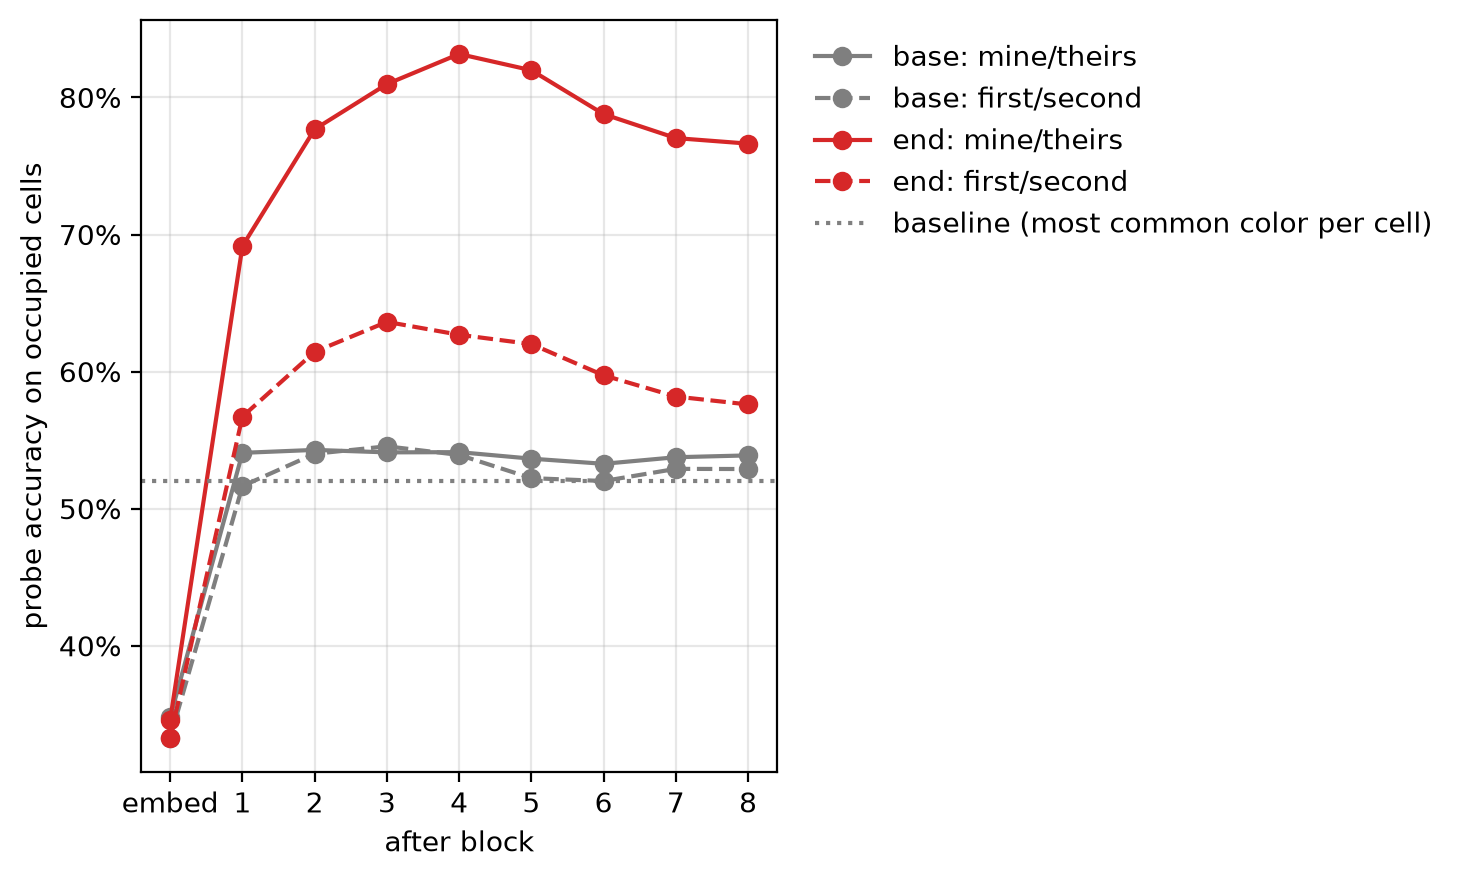

In [8]:
x = range(n_layers)
fig, ax = plt.subplots(figsize=(7.5, 4.5))
styles = {"base": "#7f7f7f", "end": "#d62728"}
for (model_name, enc), rs in results.items():
    ax.plot(x, [r["occupied"] for r in rs], marker="o", color=styles[model_name],
            ls="-" if enc == "relative" else "--", label=f"{model_name}: {'mine/theirs' if enc == 'relative' else 'first/second'}")
ax.axhline(max(baseline.values()), ls=":", color="gray", label="baseline (most common color per cell)")
ax.set_xticks(list(x), ["embed", *[str(l) for l in range(1, n_layers)]])
ax.set_xlabel("after block")
ax.set_ylabel("probe accuracy on occupied cells")
ax.yaxis.set_major_formatter(PercentFormatter(1))
ax.grid(True, alpha=0.3)
ax.legend(bbox_to_anchor=(1.02, 1), loc="upper left")
fig.tight_layout()
fig.savefig(FIG_DIR / "color_probes_base_vs_end.svg", bbox_inches="tight")
fig.savefig(FIG_DIR / "color_probes_base_vs_end.png", dpi=200, bbox_inches="tight")
plt.show()